In [14]:
# Install Tiny-SIMA and the optional VLM backend into this kernel.
import importlib
import os
import shutil
import subprocess
import sys
from pathlib import Path

# Leave room for the PyTorch VLM before importing JAX.
os.environ.setdefault(
    "XLA_PYTHON_CLIENT_MEM_FRACTION",
    os.environ.get("TINY_SIMA_JAX_MEMORY_FRACTION", "0.35"),
)

if not ((3, 11) <= sys.version_info[:2] < (3, 13)):
    raise RuntimeError("Tiny-SIMA requires Python 3.11 or 3.12.")

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the Tiny-SIMA repository.")

cuda_override = os.environ.get("TINY_SIMA_USE_CUDA")
if cuda_override is None:
    has_cuda = (
        shutil.which("nvidia-smi") is not None
        and subprocess.run(
            ["nvidia-smi"],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
            check=False,
        ).returncode == 0
    )
else:
    has_cuda = cuda_override.lower() in {"1", "true", "yes"}

extras = "notebook,vlm,cuda12" if has_cuda else "notebook,vlm"
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--quiet",
    "--no-cache-dir",
    "--disable-pip-version-check",
    "-e",
    f"{repo_root}[{extras}]",
])
# Reload edited Tiny-SIMA source on every cell execution, so iterating on the
# planner prompt costs one cell run instead of a kernel restart -- which here
# means reinstalling the package and reloading the VLM weights. Existing
# objects keep working because autoreload patches methods onto the live
# classes, and a prompt edit changes the response cache key, so the scorer
# cache cannot serve an answer to the old prompt.
ipython = get_ipython()
ipython.run_line_magic("load_ext", "autoreload")
ipython.run_line_magic("autoreload", "2")

# Import Torchvision before Transformers. Transformers caches optional
# dependency availability on first import.
torch = importlib.import_module("torch")
torchvision = importlib.import_module("torchvision")
transformers = importlib.import_module("transformers")
outlines = importlib.import_module("outlines")
transformers_utils = importlib.import_module("transformers.utils")

print(
    "PyTorch:", torch.__version__,
    "Torchvision:", torchvision.__version__,
    "Transformers:", transformers.__version__,
    "Outlines: installed",
)
if not transformers_utils.is_torchvision_available():
    raise RuntimeError(
        "Transformers cached Torchvision as unavailable. Restart this "
        "kernel, then run this installation cell before any other cell."
    )

source_root = str(repo_root / "src")
if source_root not in sys.path:
    sys.path.insert(0, source_root)

print("Repository:", repo_root)
print("CUDA detected:", has_cuda)
print("JAX memory fraction:", os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch: 2.15.0+cu132 Torchvision: 0.29.2+cu132 Transformers: 5.21.0 Outlines: installed
Repository: /home/jovyan/shared/jd.tan/tiny-sima
CUDA detected: True
JAX memory fraction: 0.35


# Phase 4b: VLM sub-goals, feasibility and a learned skill model

This notebook evaluates a frozen VLM as the high-level planner over the goal-conditioned executor, on the stone-pickaxe chains. Start it in a fresh kernel so the JAX memory fraction is applied before JAX initializes.

1. **Probing.** Every skill is probed at every chain boundary, and the outcomes fit the competence prior: the executor's measured success by `(skill, reachable, distance band)`.
2. **Can the VLM judge feasibility?** The VLM rates every skill on the probe states, and is scored against the prior and the probe outcomes (README Experiment 2).
3. **Phase 4b.** The VLM proposes sub-goals and a symbolic planner over the skill registry picks the skills. It is compared with the best per-turn arm, the scripted plans and the plan-veto upper bound on three chains (Experiment 1).
4. **Learning the skill model.** The planner's model of what each skill requires and changes is induced by the VLM from a manual and corrected from the executor's transitions, SCALAR-style (Experiment 3).

Phase 4's per-turn ablation ladder was removed once Phase 4 closed: the prompt styles and Can terms on the prefix ladder, the search, surplus and detour states, the per-turn closed loop, the sequencing diagnosis and the executor comparison. Its results are in ARCHIVE.md under "Phase 4 per-turn planner results", and the cells are at commit 282ef35. The per-turn conditions Phase 4b is compared against are rebuilt in the Phase 4b section.

Every choice is read on seed 51, and `CONFIRM = True` reruns once on seed 202.

In [15]:
import json
import time

import jax
import matplotlib.pyplot as plt
import numpy as np

from tiny_sima.config import load_vlm_planner_config
from tiny_sima.envs.craftax import render_state
from tiny_sima.evaluation import (
    COLLECT_FIRST_PLANS,
    STONE_PICKAXE_AND_SWORD_CHAIN,
    TERSE_STONE_PICKAXE_CHAIN,
    WOOD_TO_STONE_CHAIN,
    WOOD_TO_STONE_PICKAXE_CHAIN,
    chain_environment,
    collect_affordance_samples,
    compare_paired_successes,
    evaluate_affordance_calibration,
    evaluate_competence_prior,
    evaluate_skill_chain,
    fit_affordance_calibration,
    fit_affordance_competence_prior,
    json_ready_chain_result,
    load_goal_conditioned_checkpoint,
    make_learned_skill_executor,
    run_vlm_smoke_test,
)
from tiny_sima.goals import DEFAULT_REACHABILITY
from tiny_sima.memory import EpisodeMemory
from tiny_sima.planner import (
    CompetencePrior,
    PlannerContext,
    PlannerPromptStyle,
    PlanProgressFeasibility,
    SayCanPlanner,
    SequentialUtilityScorer,
    SubgoalPlanner,
    TransformersVLMBackend,
    VLMUtilityScorer,
    build_planner_prompt,
    build_planner_system_prompt,
    make_critic_affordance_scorer,
    reachability_feasibility,
)

print("JAX devices:", jax.devices())
print("Reachability view radius:", DEFAULT_REACHABILITY.view_radius)
print("Unknown-target feasibility:", DEFAULT_REACHABILITY.unknown_feasibility)

JAX devices: [CudaDevice(id=0)]
Reachability view radius: (3, 4)
Unknown-target feasibility: 0.25


In [16]:
# Notebook 07 records the randomized run it selected. It chose on its own
# benchmark seed (101), disjoint from every seed below, so the choice does not
# bias what this notebook reports. Set EXECUTOR_CHECKPOINT by hand to measure
# another run.
# Its stone_pickaxe preset writes here; rerun that selection cell after
# training a new executor and this picks it up.
EXECUTOR_SELECTION_PATH = (
    repo_root / "runs" / "executor-improvement-stone_pickaxe" / "selected_executor.json"
)
EXECUTOR_CHECKPOINT = (
    repo_root / json.loads(EXECUTOR_SELECTION_PATH.read_text())["checkpoint"]
    if EXECUTOR_SELECTION_PATH.is_file()
    else None
)
if EXECUTOR_CHECKPOINT is None:
    raise FileNotFoundError(
        f"{EXECUTOR_SELECTION_PATH} does not exist. Run notebook 07's selection "
        "cell, or set EXECUTOR_CHECKPOINT by hand."
    )
VLM_CONFIG_PATH = repo_root / "configs" / "vlm_planner_qwen3_2b.yaml"

# The stone-pickaxe chain: four wood, a table, both pickaxes and a stone, eight
# decisions with a limit of 16. The executor must know every skill in
# CHAIN.skills; the cell that loads it checks. Phase 4b adds the terse and
# pickaxe-and-sword chains beside it.
CHAIN = WOOD_TO_STONE_PICKAXE_CHAIN
# Fits are saved under the chain's name, so the recorded wood-to-stone fits
# are never overwritten.
CHAIN_SUFFIX = "" if CHAIN is WOOD_TO_STONE_CHAIN else f"_{CHAIN.name}"

# One executor, keyed by name so its fits and results are labelled.
EXECUTOR_CHECKPOINTS = {"selected": EXECUTOR_CHECKPOINT}
PRIMARY_EXECUTOR = "selected"


def run_dir(executor_name):
    # Fits and closed loops are saved beside the checkpoint they measure.
    return EXECUTOR_CHECKPOINTS[executor_name].parents[1]


# "smoke" is the cheapest end-to-end pass over every cell, and "full" is the
# reported run. Any knob below can still be overridden by hand.
EVAL_PRESET = "full"

EVAL_PRESETS = {
    "smoke": {
        "closed_loop_episodes": 2,
        "calibration_episodes": 2,
        "run_probing": True,
        "run_closed_loop": True,
    },
    "full": {
        # Closed-loop episodes run in lockstep, so the count costs batch width
        # rather than wall clock; 64 gives a standard error near 0.05.
        "closed_loop_episodes": 64,
        "calibration_episodes": 12,
        "run_probing": True,
        "run_closed_loop": True,
    },
}
if EVAL_PRESET not in EVAL_PRESETS:
    raise ValueError(f"EVAL_PRESET must be one of {sorted(EVAL_PRESETS)}.")
preset = EVAL_PRESETS[EVAL_PRESET]

RUN_VLM_SMOKE_TEST = True
# Probing is a measurement of the checkpoint, not of the planner. With it off,
# the competence prior is reloaded from disk.
RUN_AFFORDANCE_CALIBRATION = preset["run_probing"]
RUN_CLOSED_LOOP = preset["run_closed_loop"]
NUM_CLOSED_LOOP_EPISODES = preset["closed_loop_episodes"]
# Each episode probes every skill at every chain boundary. The probes run
# batched on device, so the cost is dominated by the scripted advance between
# boundaries rather than by episodes x boundaries x skills.
NUM_CALIBRATION_EPISODES = preset["calibration_episodes"]
# The prior and the feasibility blend are fitted on CALIBRATION_SEED and scored
# on CALIBRATION_EVAL_SEED. Scoring a head on the samples it was fitted on
# measures separability, not generalization.
CALIBRATION_SEED = 7
CALIBRATION_EVAL_SEED = 23
SKILL_HORIZON = 64
# Every choice is read on seed 51. CONFIRM reruns on 202, which nothing has
# been tuned against, so a choice made on 51 is checked once on unseen worlds.
# Results are saved per seed, so a confirmation run keeps 51's.
CONFIRM = False
EVALUATION_SEED = 201
# EVALUATION_SEED = 202 if CONFIRM else 51

vlm_config = load_vlm_planner_config(VLM_CONFIG_PATH)
print("VLM:", vlm_config.model_id)
print(f"Chain: {CHAIN.name}, evaluation seed: {EVALUATION_SEED}")
print(f"Executor: {EXECUTOR_CHECKPOINT} exists={EXECUTOR_CHECKPOINT.exists()}")
print("Preset:", EVAL_PRESET, preset)
print("VLM batch size:", vlm_config.max_batch_size)

VLM: Qwen/Qwen3-VL-2B-Instruct
Chain: wood_to_stone_pickaxe, evaluation seed: 201
Executor: /home/jovyan/shared/jd.tan/tiny-sima/runs/executor-improvement-stone_pickaxe/randomized-seed2/checkpoints/final exists=True
Preset: full {'closed_loop_episodes': 64, 'calibration_episodes': 12, 'run_probing': True, 'run_closed_loop': True}
VLM batch size: 8


## Inspect the planner input

The VLM receives a rendered frame plus a compact text record. This cell is cheap and should be inspected before loading model weights.

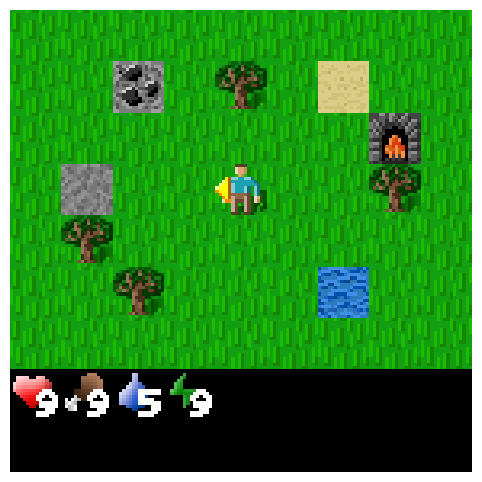

SYSTEM:
 You are the high-level planner for a Craftax survival agent.
You may rely on the supplied game-mechanics catalog as authoritative knowledge of skill requirements, resource costs, and successful effects.
At each option boundary, rank only the supplied skills by how much each advances the objective as the next requested skill from the current state.
The ranking is recomputed after every completed or failed skill.
Prioritize unmet prerequisites in execution order.
Each candidate arrives with its quantities already computed from the catalog. inventory_shortfall is how much more of each item its requirements ask for than the inventory holds, result_held is true for a craft whose tool is already in the inventory, and fills_shortfall_of lists the other candidates whose shortfall the skill reduces. Treat them as ground truth and do not recount them.
A craft whose result_held is true is a completed step. Repeat a collection skill while a remaining objective step is still short of its r

In [17]:
preview_environment = chain_environment(CHAIN)
preview_state = preview_environment.reset(jax.random.PRNGKey(EVALUATION_SEED)).state
preview_pixels = render_state(
    preview_state,
    vlm_config.environment_name,
    block_pixel_size=vlm_config.block_pixel_size,
)
plt.figure(figsize=(8, 6))
plt.imshow(preview_pixels)
plt.axis("off")
plt.show()

# The prompt of the per-turn arm Phase 4b is compared against.
preview_style = PlannerPromptStyle.RECIPE_AWARE
print("SYSTEM:\n", build_planner_system_prompt(preview_style, CHAIN.skills))
print(
    "\nUSER:\n",
    build_planner_prompt(
        preview_state,
        context=PlannerContext(objective=CHAIN.objective),
        candidate_skills=CHAIN.skills,
        style=preview_style,
    ),
)

## End-to-end VLM smoke test

This performs one real multimodal generation and verifies constrained decoding, complete-ranking validation, and symbolic grounding before the longer evaluations run.

In [18]:
backend = TransformersVLMBackend(vlm_config)
# The per-turn arm's Say term: objective_first with each candidate's inventory
# shortfall, held-tool flag and the candidates it supplies computed from the
# skill registry, because the model miscounted the recipes it was given.
vlm_recipe_aware_utility = VLMUtilityScorer(
    backend=backend,
    config=vlm_config,
    prompt_style=PlannerPromptStyle.RECIPE_AWARE,
)

if RUN_VLM_SMOKE_TEST:
    smoke_result = run_vlm_smoke_test(
        vlm_config,
        scorer=vlm_recipe_aware_utility,
        seed=EVALUATION_SEED,
    )
    print(smoke_result.to_dict())

Loading weights: 100%|██████████| 625/625 [00:00<00:00, 1458.30it/s]


{'model_id': 'Qwen/Qwen3-VL-2B-Instruct', 'elapsed_seconds': 8.05844167000032, 'ranking': ('craft_wood_pickaxe', 'collect_wood', 'collect_stone', 'place_table', 'drink_water', 'craft_wood_sword'), 'utility_selected_skill': 'craft_wood_pickaxe', 'grounded_selected_skill': 'collect_wood', 'grounded_feasibility': 1.0, 'progress_assessment': 'Objective: Craft wooden pickaxe, use it to collect stone. Current state: No pickaxe, 3 wood, 2/3', 'raw_response': '{ "progress_assessment": "Objective: Craft wooden pickaxe, use it to collect stone. Current state: No pickaxe, 3 wood, 2/3" ,"selected_skill": "craft_wood_pickaxe" ,"ranking": [ "craft_wood_pickaxe", "collect_wood", "collect_stone", "place_table", "drink_water","craft_wood_sword"] }'}


## Probe the skills, then fit the competence prior

Every skill is probed at every chain boundary from a copy of the boundary state, on device and batched, and labelled with whether the executor finished it within `SKILL_HORIZON` steps. The probe states are reached by the scripted oracle, not by the executor under test.

The labels fit the competence prior, `fit_affordance_competence_prior`. It tabulates success by `(skill, reachable, distance band)` and shrinks each cell toward its parent, so a thin cell inherits an estimate instead of reading 0 or 1. Samples whose symbolic precondition failed are dropped, because the precondition vetoes at scoring time anyway. The prior is the Can term of the per-turn arm and the sub-goal planner's tie-break, and the feasibility study scores the VLM against it on the same probes.

The prior is fitted on `CALIBRATION_SEED` and scored on `CALIBRATION_EVAL_SEED`. The critic-as-affordance fit is still measured and saved beside it, so its held-out AUC is reproduced, but no planner uses it: the curriculum always places a reachable target, so the critic encodes which skill was requested rather than whether the state admits it.

`unreachable_successes` counts skills the reachability predicate called unreachable that the executor completed anyway by walking out of the observation window. Every one is an episode a hard gate would have thrown away, which is why the prior grades rather than vetoes.

The fits are saved beside the checkpoint, and `CompetencePrior.load(run_dir(PRIMARY_EXECUTOR) / f"competence_prior{CHAIN_SUFFIX}.json")` reloads the prior when probing is off.

In [19]:
for executor_name, path in EXECUTOR_CHECKPOINTS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {executor_name} executor checkpoint: {path}")

# One load per executor, shared by its affordance scorer and its closed-loop
# executor, so the critic being measured belongs to the policy under test.
checkpoints = {
    executor_name: load_goal_conditioned_checkpoint(path)
    for executor_name, path in EXECUTOR_CHECKPOINTS.items()
}
executors = {
    executor_name: make_learned_skill_executor(checkpoint, deterministic=False)
    for executor_name, checkpoint in checkpoints.items()
}
for executor_name, executor in executors.items():
    missing = [skill for skill in CHAIN.skills if skill not in executor.skill_ids]
    if missing:
        raise ValueError(
            f"The {executor_name} executor was not trained on "
            f"{[skill.value for skill in missing]}, which {CHAIN.name} needs. "
            "Train a seven-skill executor in notebook 07 and select it."
        )
for executor_name, checkpoint in checkpoints.items():
    print(
        f"{executor_name}: scenario={checkpoint.config.skill_scenario} "
        f"skill_horizon={checkpoint.config.skill_horizon} "
        f"gamma={checkpoint.config.gamma} "
        f"skills={checkpoint.config.num_skills}"
    )


def print_calibration(report, competence_report):
    print("critic overall:", json.dumps(report["overall"], indent=2, default=float))
    print(
        "competence overall:",
        json.dumps(competence_report["overall"], indent=2, default=float),
    )
    print(
        f"base_rate={competence_report['base_rate']:.3f} "
        f"unreachable_rate={report['unreachable_rate']:.3f} "
        f"unreachable_successes={report['unreachable_successes']} "
        f"reachable_success_rate={report['reachable_success_rate']:.3f} "
        f"unreachable_success_rate={report['unreachable_success_rate']:.3f}"
    )
    # Two populations, each read against its own success rate. The critic is
    # scored on every probe; the prior only on probes whose precondition held,
    # because the precondition vetoes the rest at scoring time. Reading the
    # prior against the all-probe rate made a well-calibrated place_table
    # look like 0.98 predicted against 0.17 observed.
    print(f"\n{'':22s} {'critic, all probes':>30s} | {'prior, precondition held':>24s}")
    print(
        f"{'skill':22s} {'n':>4s} {'mean_value':>10s} {'auc':>6s} "
        f"{'success':>7s} | {'n':>4s} {'prior_p':>8s} {'success':>8s}"
    )
    for skill_name, metrics in report["per_skill"].items():
        prior_metrics = competence_report["per_skill"].get(skill_name, {})
        print(
            f"{skill_name:22s} {int(metrics['num_samples']):4d} "
            f"{metrics['mean_critic_value']:10.3f} {metrics['auc']:6.3f} "
            f"{metrics['success_rate']:7.3f} | "
            f"{int(prior_metrics.get('num_samples', 0)):4d} "
            f"{prior_metrics.get('mean_probability', float('nan')):8.3f} "
            f"{prior_metrics.get('success_rate', float('nan')):8.3f}"
        )


competence_priors = {}
competence_reports = {}
held_out_samples = {}
for executor_name, checkpoint in checkpoints.items():
    calibration_path = run_dir(executor_name) / (
        f"affordance_calibration{CHAIN_SUFFIX}.json"
    )
    prior_path = run_dir(executor_name) / f"competence_prior{CHAIN_SUFFIX}.json"
    if not RUN_AFFORDANCE_CALIBRATION:
        # The critic fit is still measured and saved whenever probing runs, so
        # its AUC is reproduced, but no planner uses it any more.
        competence_priors[executor_name] = (
            CompetencePrior.load(prior_path) if prior_path.exists() else None
        )
        continue

    uncalibrated_affordance = make_critic_affordance_scorer(checkpoint)
    started = time.perf_counter()
    fit_samples = collect_affordance_samples(
        uncalibrated_affordance,
        executors[executor_name],
        chain=CHAIN,
        num_episodes=NUM_CALIBRATION_EPISODES,
        seed=CALIBRATION_SEED,
        candidate_skills=CHAIN.skills,
        skill_horizon=SKILL_HORIZON,
    )
    held_out_samples[executor_name] = collect_affordance_samples(
        uncalibrated_affordance,
        executors[executor_name],
        chain=CHAIN,
        num_episodes=NUM_CALIBRATION_EPISODES,
        seed=CALIBRATION_EVAL_SEED,
        candidate_skills=CHAIN.skills,
        skill_horizon=SKILL_HORIZON,
    )
    probe_seconds = time.perf_counter() - started

    calibration = fit_affordance_calibration(fit_samples)
    calibration.save(calibration_path)
    competence_priors[executor_name] = fit_affordance_competence_prior(
        fit_samples,
        skills=CHAIN.skills,
    )
    competence_priors[executor_name].save(prior_path)

    report = evaluate_affordance_calibration(
        held_out_samples[executor_name],
        calibration,
    )
    competence_reports[executor_name] = evaluate_competence_prior(
        held_out_samples[executor_name],
        competence_priors[executor_name],
    )
    print(
        f"\n=== {executor_name} executor ===\n"
        f"fit_samples={len(fit_samples)} "
        f"held_out_samples={report['num_samples']} "
        f"held_out={report['held_out']} "
        f"seconds={probe_seconds:.1f}"
    )
    print_calibration(report, competence_reports[executor_name])

competence_prior = competence_priors[PRIMARY_EXECUTOR]
competence_report = competence_reports.get(PRIMARY_EXECUTOR)

selected: scenario=randomized skill_horizon=64 gamma=0.95 skills=7

=== selected executor ===
fit_samples=672 held_out_samples=672 held_out=True seconds=166.3
critic overall: {
  "num_samples": 672.0,
  "base_rate": 0.47767857142857145,
  "auc": 0.4566214908894037,
  "raw_brier": 0.41255665998053076,
  "raw_ece": 0.3881842216388101,
  "calibrated_brier": 0.2521602110360879,
  "calibrated_ece": 0.010028477106880946
}
competence overall: {
  "num_samples": 324.0,
  "base_rate": 0.9907407407407407,
  "auc": 0.9169262720664589,
  "raw_brier": 0.008979493902913473,
  "raw_ece": 0.006455285005087186
}
base_rate=0.991 unreachable_rate=0.609 unreachable_successes=58 reachable_success_rate=1.000 unreachable_success_rate=0.142

                                   critic, all probes | prior, precondition held
skill                     n mean_value    auc success |    n  prior_p  success
collect_stone            96      0.855  0.566   0.375 |   36    0.999    1.000
collect_wood             96      

In [20]:
# The fitted table, cell by cell. `fit_support` is how many probes the cell was
# estimated from and `probability` is the shrunk estimate, so a small support
# next to a probability near its neighbours is shrinkage doing its job rather
# than evidence. `success_rate` is the held-out outcome on the same rows.
if competence_prior is None:
    print("No competence prior available; run the cell above or fit one.")
else:
    print(f"executor: {PRIMARY_EXECUTOR}")
    print(
        f"{'skill':22s} {'band':>18s} {'fit_n':>6s} {'p':>6s} "
        f"{'eval_n':>7s} {'success':>8s}"
    )
    rows = competence_report["cells"] if competence_report is not None else []
    for cell in rows:
        print(
            f"{cell['skill']:22s} {cell['label']:>18s} "
            f"{cell['fit_support']:6d} {cell['probability']:6.3f} "
            f"{cell['num_samples']:7d} {cell['success_rate']:8.3f}"
        )
    if not rows:
        print("(loaded from disk; re-run probing to score it on held-out states)")
    print("\ndistance bands:", competence_prior.distance_edges)
    print("floor:", competence_prior.floor)
    print("fitted base rate:", round(competence_prior.base_rate, 3))

executor: selected
skill                                band  fit_n      p  eval_n  success
collect_wood                  unreachable     10  0.996      11    0.909
collect_wood                     steps<=2     29  1.000      25    1.000
collect_wood                  3<=steps<=6     56  1.000      58    1.000
collect_wood                      steps>6      1  1.000       2    1.000
collect_stone                 unreachable      4  0.993       6    1.000
collect_stone                    steps<=2     10  1.000      13    1.000
collect_stone                 3<=steps<=6     21  1.000      15    1.000
collect_stone                     steps>6      1  1.000       2    1.000
drink_water                   unreachable     37  0.974      29    0.931
drink_water                      steps<=2     12  1.000       8    1.000
drink_water                   3<=steps<=6     46  1.000      58    1.000
drink_water                       steps>6      1  1.000       1    1.000
place_table                     

## Can the VLM judge when a skill will succeed?

Every Can term so far was fitted from the executor's side: the competence prior tabulates probe outcomes by `(skill, reachable, distance band)`, and the critic was measured and retired. This section asks the reverse question - whether the frozen VLM itself can tell when the controller will complete a skill - and scores its answer against the probe outcomes recorded at the very same states.

One request per boundary state asks the model to rate every candidate skill from 0 to 10 for how likely the controller is to complete it within `SKILL_HORIZON` steps; the rating is read as `r / 10`. The prompt carries the mechanics catalog and the planner's structured state, and nothing about the objective, since feasibility does not depend on it. Four predictors are scored on `CALIBRATION_EVAL_SEED`, on the probes whose precondition held, as the prior is:

| predictor | what it is |
| --- | --- |
| `prior` | the competence prior fitted above on `CALIBRATION_SEED` |
| `vlm` | the VLM's rating / 10 |
| `product` | `prior * vlm`, the naive combination |
| `blend` | `sigmoid(a logit(prior) + b logit(vlm) + c)`, fitted on `CALIBRATION_SEED` |

The blend's weights are the headline: `b` near zero means the VLM adds nothing the prior does not already know. `vlm_all_samples` scores the VLM on every probe, the precondition failures included, which shows whether it knows the requirements as well as the odds.

`affordance_boundary_states` replays the probe walk without the probes to recover the states, and `check_boundary_states` confirms every sample's recorded precondition and distance against its replayed state before anything is rated. The structured state includes the `world` reachability readout - the same distances the prior conditions on - so set `FEASIBILITY_INCLUDE_WORLD = False` to see what the model judges from the scene alone.

In [21]:
from tiny_sima.evaluation import (
    VLMFeasibilityRater,
    affordance_boundary_states,
    check_boundary_states,
    evaluate_vlm_feasibility,
)
from tiny_sima.planner.observation import TEXT_ONLY

RUN_VLM_FEASIBILITY = True
# Observation arms: None is the screenshot alone, TEXT_ONLY the text map with
# vitals, mobs and achievements and no image.
FEASIBILITY_OBSERVATIONS = {
    "image_only": None,
    "text_only": TEXT_ONLY,
}
FEASIBILITY_INCLUDE_WORLD = True

feasibility_studies = {}
if RUN_VLM_FEASIBILITY:
    feasibility_prior = competence_priors.get(PRIMARY_EXECUTOR)
    if feasibility_prior is None:
        raise ValueError("No competence prior; run the probing cell or fit one.")
    # The probing cell keeps the held-out samples per executor, but only the
    # last executor's fit samples. Re-probe when those are not the primary's.
    if (
        PRIMARY_EXECUTOR in held_out_samples
        and list(checkpoints)[-1] == PRIMARY_EXECUTOR
    ):
        feasibility_fit_samples = fit_samples
        feasibility_test_samples = held_out_samples[PRIMARY_EXECUTOR]
    else:
        feasibility_scorer = make_critic_affordance_scorer(
            checkpoints[PRIMARY_EXECUTOR]
        )
        feasibility_fit_samples, feasibility_test_samples = (
            collect_affordance_samples(
                feasibility_scorer,
                executors[PRIMARY_EXECUTOR],
                chain=CHAIN,
                num_episodes=NUM_CALIBRATION_EPISODES,
                seed=seed,
                candidate_skills=CHAIN.skills,
                skill_horizon=SKILL_HORIZON,
            )
            for seed in (CALIBRATION_SEED, CALIBRATION_EVAL_SEED)
        )

    started = time.perf_counter()
    feasibility_fit_states, feasibility_test_states = (
        affordance_boundary_states(
            chain=CHAIN,
            num_episodes=NUM_CALIBRATION_EPISODES,
            seed=seed,
            skill_horizon=SKILL_HORIZON,
        )
        for seed in (CALIBRATION_SEED, CALIBRATION_EVAL_SEED)
    )
    check_boundary_states(feasibility_fit_samples, feasibility_fit_states)
    check_boundary_states(feasibility_test_samples, feasibility_test_states)
    print(
        f"replayed {len(feasibility_fit_states)} fit and "
        f"{len(feasibility_test_states)} held-out states in "
        f"{time.perf_counter() - started:.1f}s; every sample matches its state"
    )

    for arm, observation in FEASIBILITY_OBSERVATIONS.items():
        rater = VLMFeasibilityRater(
            backend,
            config=vlm_config,
            candidate_skills=CHAIN.skills,
            observation=observation,
            skill_horizon=SKILL_HORIZON,
            include_world=FEASIBILITY_INCLUDE_WORLD,
        )
        started = time.perf_counter()
        feasibility_studies[arm] = evaluate_vlm_feasibility(
            rater,
            feasibility_prior,
            feasibility_fit_samples,
            feasibility_fit_states,
            feasibility_test_samples,
            feasibility_test_states,
        )
        study = feasibility_studies[arm]
        print(
            f"{arm}: {study.num_states} states rated in "
            f"{time.perf_counter() - started:.1f}s, "
            f"invalid_responses={study.num_invalid_responses} "
            f"missing_ratings={study.num_missing_ratings}"
        )

    _, example_request = rater.request(
        feasibility_test_states[min(feasibility_test_states)]
    )
    print("\nSYSTEM (last arm):\n", example_request.system_prompt)
    print("\nUSER (last arm):\n", example_request.user_prompt)

replayed 96 fit and 96 held-out states in 74.4s; every sample matches its state
image_only: 192 states rated in 95.3s, invalid_responses=0 missing_ratings=0
text_only: 192 states rated in 94.6s, invalid_responses=0 missing_ratings=0

SYSTEM (last arm):
 You judge skills for a Craftax survival agent. You do not choose what to do next.
Each skill is carried out by a learned low-level controller that walks to the skill's target and interacts with it. The skill succeeds when its effect happens within 64 environment steps, and fails when the steps run out or its requirements are not met.
Rate every candidate skill from 0 to 10 for how likely the controller is to complete it from the current state: 0 means it cannot succeed, 10 means it is certain to. Rate feasibility, not usefulness: a skill that does nothing for any objective can still deserve a 10.
Weigh the requirements in the mechanics catalog, what the local map shows, and how far the player would have to walk. The catalog's reachabili

In [22]:
def fmt(value, width=6):
    return f"{'nan':>{width}s}" if value != value else f"{value:{width}.3f}"


for arm, study in feasibility_studies.items():
    blend = study.blend
    print(
        f"\n=== {arm} === fit_n={study.num_fit_samples} "
        f"test_n={study.num_test_samples} "
        f"blend: a(prior)={blend.prior_weight:+.2f} "
        f"b(vlm)={blend.vlm_weight:+.2f} c={blend.intercept:+.2f}"
    )
    print(f"{'predictor':10s} {'auc':>6s} {'ece':>6s} {'brier':>6s} {'mean_p':>6s}")
    for name, metrics in study.overall.items():
        print(
            f"{name:10s} {fmt(metrics['auc'])} {fmt(metrics['ece'])} "
            f"{fmt(metrics['brier'])} {fmt(metrics['mean_probability'])}"
        )
    print(
        f"{'vlm, all':10s} {fmt(study.vlm_all_samples['auc'])} "
        f"{fmt(study.vlm_all_samples['ece'])} "
        f"{fmt(study.vlm_all_samples['brier'])} "
        f"{fmt(study.vlm_all_samples['mean_probability'])}"
        "   (precondition failures included)"
    )
    print(
        f"\n{'skill':22s} {'n':>4s} {'success':>7s} {'rating':>6s} "
        f"{'prior_p':>7s} | {'auc: prior':>10s} {'vlm':>6s} {'prod':>6s} "
        f"{'blend':>6s} | {'ece: prior':>10s} {'vlm':>6s} {'blend':>6s}"
    )
    for skill_name, row in study.per_skill.items():
        print(
            f"{skill_name:22s} {row['num_samples']:4d} "
            f"{row['success_rate']:7.3f} {fmt(row['mean_rating'])} "
            f"{row['prior']['mean_probability']:7.3f} | "
            f"{fmt(row['prior']['auc'], 10)} {fmt(row['vlm']['auc'])} "
            f"{fmt(row['product']['auc'])} {fmt(row['blend']['auc'])} | "
            f"{fmt(row['prior']['ece'], 10)} {fmt(row['vlm']['ece'])} "
            f"{fmt(row['blend']['ece'])}"
        )

if feasibility_studies:
    feasibility_path = run_dir(PRIMARY_EXECUTOR) / (
        f"vlm_feasibility{CHAIN_SUFFIX}_fit{CALIBRATION_SEED}_"
        f"eval{CALIBRATION_EVAL_SEED}_n{NUM_CALIBRATION_EPISODES}.json"
    )
    feasibility_path.write_text(
        json.dumps(
            {
                "executor": PRIMARY_EXECUTOR,
                "chain": CHAIN.name,
                "model_id": vlm_config.model_id,
                "fit_seed": CALIBRATION_SEED,
                "eval_seed": CALIBRATION_EVAL_SEED,
                "num_episodes": NUM_CALIBRATION_EPISODES,
                "skill_horizon": SKILL_HORIZON,
                "arms": {
                    arm: study.to_dict() for arm, study in feasibility_studies.items()
                },
            },
            indent=2,
        )
    )
    print("\nsaved", feasibility_path)


=== image_only === fit_n=324 test_n=324 blend: a(prior)=+1.69 b(vlm)=+0.42 c=-2.17
predictor     auc    ece  brier mean_p
prior       0.917  0.006  0.009  0.997
vlm         0.677  0.144  0.041  0.846
product     0.818  0.147  0.041  0.844
blend       0.879  0.007  0.009  0.997
vlm, all    0.526  0.376  0.394  0.846   (precondition failures included)

skill                     n success rating prior_p | auc: prior    vlm   prod  blend | ece: prior    vlm  blend
collect_wood             96   0.990  8.625   1.000 |      0.947  0.816  0.900  0.816 |      0.010  0.127  0.009
collect_stone            36   1.000  7.278   0.999 |        nan    nan    nan    nan |      0.001  0.272  0.003
drink_water              96   0.979  8.427   0.992 |      0.856  0.625  0.795  0.822 |      0.013  0.136  0.018
place_table              12   1.000  7.750   1.000 |        nan    nan    nan    nan |      0.000  0.225  0.002
craft_wood_pickaxe       36   1.000  8.944   0.999 |        nan    nan    nan    nan |

## Phase 4b: VLM sub-goals over a symbolic planner

The plan veto solved the stone-pickaxe chain in Phase 4 (`recipe_aware_plus_plan`, 64 of 64), but it reads the chain's formal goal, which we wrote, and world facts scanned from the whole 64x64 map, which the agent cannot see. It stays as the upper bound. This section measures the Phase 4b design, in which nothing but the objective text reaches the planner.

- **The VLM sets the sub-goals.** It reads the objective, the frame, the inventory and the episode memory, and returns up to four schema-constrained sub-goals such as `inventory.stone_pickaxe >= 1`. It never picks a skill.
- **A symbolic planner checks and follows them.** It checks each sub-goal against the registry and picks every skill as the first step of a shortest plan to the current sub-goal. A sub-goal it cannot reach goes back to the VLM with the reason.
- **The VLM is asked again only on a trigger:** episode start, all sub-goals reached, a failed skill, low drink, or the current sub-goal becoming unreachable.
- **World facts come from memory.** Resources seen in the agent's view stay in memory, and a resource is ruled out after repeated failed searches. The map scan is used only by `subgoal_vlm_map_scan`, which isolates the cost of the belief.

Conditions, on each chain:

| condition | sub-goals from | skills from | world facts |
|---|---|---|---|
| `scripted_oracle`, `scripted_collect_first` | none | the chain's reference plan, or collect-first (the bar) | view-limited |
| `recipe_aware_plus_competence_prior` | none (per-turn VLM) | VLM ranking × competence prior | view-limited |
| `subgoal_vlm_memory` | VLM | symbolic planner | memory |
| `subgoal_vlm_map_scan` | VLM | symbolic planner | full-map scan (privileged) |
| `subgoal_formal_goal` | the chain's formal goal | symbolic planner | memory |
| `recipe_aware_plus_plan` | the formal goal, as a veto | VLM ranking within the plan | full-map scan (upper bound) |

The chains, all on the stone-pickaxe executor:

- `wood_to_stone_pickaxe` spells out the steps.
- `stone_pickaxe_terse` says only "Get a stone pickaxe."
- `stone_pickaxe_and_sword` adds a second goal and five trees, with a decision limit of 20.

A gap between `subgoal_formal_goal` and `subgoal_vlm_memory` is the VLM's decomposition error. A gap between `subgoal_vlm_memory` and the per-turn arm is what the hierarchy buys. A gap between `subgoal_vlm_memory` and `recipe_aware_plus_plan` is the price of not reading the formal goal and the whole map.

In [23]:
RUN_SUBGOAL_LOOP = RUN_CLOSED_LOOP
SUBGOAL_CHAINS = (CHAIN, TERSE_STONE_PICKAXE_CHAIN, STONE_PICKAXE_AND_SWORD_CHAIN)


class FormalGoalBackend:
    """Answer every sub-goal request with the chain's own formal goal.

    It stands in for the VLM to give the hierarchy's ceiling under the memory
    belief: the decomposition is exact, so any failure left is the planner's,
    the memory's or the executor's.
    """

    def __init__(self, goal):
        self.response = json.dumps(
            {
                "assessment": "formal goal",
                "subgoals": [
                    {"field": requirement.field, "at_least": int(requirement.value)}
                    for requirement in goal
                ],
            }
        )

    def generate(self, request):
        return self.response


def subgoal_planners_for(chain, prior):
    tie_break = prior if prior is not None else reachability_feasibility
    plan_veto = PlanProgressFeasibility(chain.goal, skills=chain.skills)
    planners = {
        "scripted_oracle": SayCanPlanner(
            candidate_skills=chain.skills,
            utility_scorer=SequentialUtilityScorer(chain.reference_skills),
        ),
        "scripted_collect_first": SayCanPlanner(
            candidate_skills=chain.skills,
            utility_scorer=SequentialUtilityScorer(COLLECT_FIRST_PLANS[chain.name]),
        ),
        "recipe_aware_plus_plan": SayCanPlanner(
            candidate_skills=chain.skills,
            utility_scorer=vlm_recipe_aware_utility,
            feasibility_scorer=plan_veto,
        ),
        "subgoal_formal_goal": SubgoalPlanner(
            FormalGoalBackend(chain.goal),
            candidate_skills=chain.skills,
            config=vlm_config,
            tie_break=tie_break,
        ),
        "subgoal_vlm_memory": SubgoalPlanner(
            backend,
            candidate_skills=chain.skills,
            config=vlm_config,
            tie_break=tie_break,
        ),
        "subgoal_vlm_map_scan": SubgoalPlanner(
            backend,
            candidate_skills=chain.skills,
            config=vlm_config,
            tie_break=tie_break,
            use_memory_belief=False,
        ),
    }
    if prior is not None:
        planners["recipe_aware_plus_competence_prior"] = SayCanPlanner(
            candidate_skills=chain.skills,
            utility_scorer=vlm_recipe_aware_utility,
            feasibility_scorer=prior,
        )
    return planners


def subgoal_stats(result):
    """Per-episode VLM calls, rejections and sub-goal outcomes, from the traces."""

    calls, rejections, invalid, statuses = [], [], [], {}
    for episode in result["episodes"]:
        plans = [
            step["plan_state"] for step in episode["trace"] if "plan_state" in step
        ]
        if "final_plan_state" in episode:
            plans.append(episode["final_plan_state"])
        if not plans:
            continue
        calls.append(plans[-1]["vlm_calls"])
        rejections.append(plans[-1]["rejections"])
        invalid.append(plans[-1]["invalid_responses"])
        for plan in plans:
            for event in plan["events"]:
                statuses[event["status"]] = statuses.get(event["status"], 0) + 1
    if not calls:
        return None
    return {
        "mean_vlm_calls": float(np.mean(calls)),
        "mean_rejections": float(np.mean(rejections)),
        "mean_invalid_responses": float(np.mean(invalid)),
        "event_counts": statuses,
    }


SUBGOAL_COMPARISONS = (
    (
        "recipe_aware_plus_competence_prior",
        "subgoal_vlm_memory",
        "sub-goals against per-turn skills",
    ),
    ("subgoal_formal_goal", "subgoal_vlm_memory", "VLM decomposition error"),
    ("subgoal_vlm_map_scan", "subgoal_vlm_memory", "memory belief against map scan"),
    ("subgoal_vlm_memory", "recipe_aware_plus_plan", "distance to the upper bound"),
    ("scripted_collect_first", "subgoal_vlm_memory", "against the best fixed plan"),
)

subgoal_results = {}
if RUN_SUBGOAL_LOOP:
    executor = executors[PRIMARY_EXECUTOR]
    prior = competence_priors[PRIMARY_EXECUTOR]
    for chain in SUBGOAL_CHAINS:
        print(f"\n=== {chain.name}: {chain.objective!r} ===")
        results = {}
        for name, planner in subgoal_planners_for(chain, prior).items():
            started = time.perf_counter()
            result = evaluate_skill_chain(
                executor,
                planner=planner,
                chain=chain,
                num_episodes=NUM_CLOSED_LOOP_EPISODES,
                seed=EVALUATION_SEED,
                skill_horizon=SKILL_HORIZON,
                memory_factory=EpisodeMemory,
            )
            summary = json_ready_chain_result(result)
            summary["episode_successes"] = [
                bool(episode.succeeded) for episode in result["episodes"]
            ]
            summary["subgoal_stats"] = subgoal_stats(summary)
            results[name] = summary
            print(
                f"{name:36s} success={summary['success_rate']:.3f} "
                f"skills={summary['mean_completed_skills']:.2f} "
                f"seconds={time.perf_counter() - started:.2f} "
                f"terminations={summary['termination_counts']}"
            )
            if summary["subgoal_stats"] is not None:
                print(f"  {summary['subgoal_stats']}")
            if summary["planner_error_counts"]:
                print(f"  planner_errors={summary['planner_error_counts']}")
        subgoal_results[chain.name] = results

        print(
            f"\n{'reference':36s} {'candidate':36s} {'both':>4s} "
            f"{'ref_only':>8s} {'cand_only':>9s} {'diff':>6s} {'p':>6s}  isolates"
        )
        for reference, candidate, isolates in SUBGOAL_COMPARISONS:
            if reference not in results or candidate not in results:
                continue
            comparison = compare_paired_successes(
                results[reference], results[candidate]
            )
            print(
                f"{reference:36s} {candidate:36s} {comparison['both']:4d} "
                f"{comparison['reference_only']:8d} "
                f"{comparison['candidate_only']:9d} "
                f"{comparison['difference']:+6.3f} {comparison['p_value']:6.3f}  "
                f"{isolates}"
            )

    (
        run_dir(PRIMARY_EXECUTOR)
        / f"subgoal_loop_seed{EVALUATION_SEED}_n{NUM_CLOSED_LOOP_EPISODES}.json"
    ).write_text(json.dumps(subgoal_results, indent=2, default=float))

    # Every sub-goal set the VLM proposed at the start of the first episodes,
    # and what the planner made of it.
    for chain_name, results in subgoal_results.items():
        print(f"\n{chain_name}, subgoal_vlm_memory, first decision:")
        for index, episode in enumerate(results["subgoal_vlm_memory"]["episodes"][:4]):
            plan = (
                episode["trace"][0]["plan_state"]
                if episode["trace"]
                else episode.get("final_plan_state")
            )
            if plan is None:
                continue
            events = [f"{e['subgoal']}: {e['status']}" for e in plan["events"]]
            print(f"  episode {index}: pending={plan['pending']} events={events}")
else:
    print("Sub-goal closed loop skipped.")


=== wood_to_stone_pickaxe: 'Craft a wooden pickaxe, use it to collect stone, and craft a stone pickaxe.' ===
scripted_oracle                      success=0.969 skills=7.94 seconds=64.09 terminations={'success': 62, 'no_viable_skill': 0, 'failure_limit': 2, 'decision_limit': 0, 'invalid_planner_output': 0}
scripted_collect_first               success=1.000 skills=8.00 seconds=62.52 terminations={'success': 64, 'no_viable_skill': 0, 'failure_limit': 0, 'decision_limit': 0, 'invalid_planner_output': 0}
recipe_aware_plus_plan               success=0.969 skills=7.86 seconds=368.18 terminations={'success': 62, 'no_viable_skill': 0, 'failure_limit': 2, 'decision_limit': 0, 'invalid_planner_output': 0}
subgoal_formal_goal                  success=0.984 skills=8.00 seconds=49.94 terminations={'success': 63, 'no_viable_skill': 0, 'failure_limit': 1, 'decision_limit': 0, 'invalid_planner_output': 0}
  {'mean_vlm_calls': 1.109375, 'mean_rejections': 0.0, 'mean_invalid_responses': 0.0, 'event_coun

## Learning the skill model (SCALAR-style)

Every symbolic planner above searches the registry's hand-written mechanics: what each skill requires and what it changes. This section asks whether the model can be learned instead, following SCALAR (arXiv 2603.09036):

1. **Induction.** The frozen VLM reads `docs/craftax_classic_manual.md`, which names every recipe's ingredients and stations but none of their amounts, and writes each skill's `requires` and `effects` over the planner's fields under a constrained schema. The request is text only.
2. **Validation.** Every skill's requirements must be reachable from the episode start by the other skills, every skill must change a field, and no two may change the same fields. A failing model goes back to the VLM once with its violations, and skills still failing are dropped.
3. **Correction.** After each round of `MODEL_EPISODES_PER_ROUND` closed-loop episodes, the successful transitions fix each skill's inventory effects (the mode of the observed change, with the executor's mid-skill inventory extremes catching wood gathered and spent within one skill) and its requirements (a field spent `c` requires `at_least c`; another count held before every success requires its minimum after `min_support` successes).
4. **Failure analysis.** Failures the model predicted to succeed, with an `infeasible` or `precondition_lost` cause, go back to the VLM beside successful pre-states, and it may name one missing requirement.

Three starting models - the registry, the VLM's induction, and the registry with one corruption (`MODEL_CORRUPTION`, by default a table costing 1 wood instead of 2) - each run `MODEL_ROUNDS` rounds, uncorrected and corrected, under two planners that read the model: the plan veto (constant utility, every skill off the model's shortest plans vetoed), and `SubgoalPlanner` given the chain's formal goal, so the VLM's decomposition is out of the picture. Round `r` runs on the same worlds in every arm, so uncorrected and corrected are paired.

`wasted` counts failed requests plus successful skills beyond the registry's shortest plan from each solved episode's start. `diff` counts the field-level differences from the registry that the model still has. Expect a few added requirements to survive correction even from a perfect start: on this chain the stone pickaxe is always crafted with a wood pickaxe held, and stone is usually mined with a wood still held, so those counts look required. They are harmless here - the plan satisfies them anyway - and only a run that broke the pattern could remove them.

In [24]:
import dataclasses

from tiny_sima.planner.model_learning import (
    induce_model,
    load_manual,
    model_diff,
    model_from_dict,
)
from tiny_sima.planner.model_rounds import (
    corrupt_registry,
    plan_veto_planner,
    run_model_learning_rounds,
    subgoal_planner_factory,
)
from tiny_sima.planner.symbolic import REGISTRY_MODEL

RUN_MODEL_LEARNING = RUN_CLOSED_LOOP
MODEL_ROUNDS = 3
MODEL_EPISODES_PER_ROUND = 16
MODEL_CORRUPTION = "table_costs_1_wood"
# Ask the VLM for a missing requirement after each corrected round.
MODEL_FAILURE_ANALYSIS = True
# The induced model is about 700 tokens of JSON; the planner's budget is not
# enough for it.
MODEL_INDUCTION_MAX_NEW_TOKENS = 1024
# The VLM backend samples only when vlm_config does, so one answer is enough
# under greedy decoding.
MODEL_INDUCTION_REPEATS = 1 if not vlm_config.do_sample else 3

manual = load_manual()
planner_config = backend.config
backend.config = dataclasses.replace(
    planner_config, max_new_tokens=MODEL_INDUCTION_MAX_NEW_TOKENS
)
try:
    started = time.time()
    induced = induce_model(
        backend,
        CHAIN.skills,
        manual=manual,
        repeats=MODEL_INDUCTION_REPEATS,
        repair=True,
        drop_invalid=True,
    )
finally:
    backend.config = planner_config
print(f"induction: {time.time() - started:.1f}s, repaired={induced.repaired}")
print("parse problems:", list(induced.problems) or "none")
for question in induced.questions:
    print(f"asked: {question.question}\n  -> {question.answer}: {question.change or 'no change'}")
violations = [str(violation) for violation in induced.report.violations]
print("violations:", violations or "none")
print("dropped:", [skill_id.value for skill_id in induced.dropped] or "none")
print("induced vs registry:")
for change in model_diff(REGISTRY_MODEL, induced.model):
    print(f"  {change}")

starting_models = {
    "registry": REGISTRY_MODEL,
    "vlm_induced": induced.model,
    f"corrupted_{MODEL_CORRUPTION}": corrupt_registry(MODEL_CORRUPTION),
}

induction: 77.6s, repaired=True
parse problems: none
asked: Collect stone with a wood pickaxe: must the player hold a wood pickaxe first?
  -> yes: collect_stone now needs inventory.wood_pickaxe >= 1, not inventory.wood_pickaxe == 0
asked: world.crafting_table_reachable is 1 while a crafting table is within reach, else 0. It is 0 at the start of every episode. Which skill makes it 1?
  -> place_table: place_table now brings about world.crafting_table_reachable == 1
asked: Craft a wood pickaxe at a crafting table: must the player hold stone first?
  -> no: dropped: craft_wood_pickaxe needs inventory.stone >= 1
violations: none
dropped: none
induced vs registry:
  drink_water.requires: survival.drink less_than 9 -> -
  drink_water.effects: survival.drink increase 1 -> decrease 1
  place_table.requires: inventory.wood at_least 2 -> -
  place_table.effects: inventory.stone - -> decrease 1
  place_table.effects: inventory.stone_pickaxe - -> decrease 1
  place_table.effects: inventory.wood d

In [25]:
model_learning_planners = {
    "plan_veto": plan_veto_planner(CHAIN),
    "subgoal_formal_goal": subgoal_planner_factory(
        FormalGoalBackend(CHAIN.goal),
        CHAIN,
        config=vlm_config,
        tie_break=reachability_feasibility,
    ),
}
model_learning_results = {}
if RUN_MODEL_LEARNING:
    executor = executors[PRIMARY_EXECUTOR]
    for start_name, start_model in starting_models.items():
        for planner_name, factory in model_learning_planners.items():
            for arm in ("uncorrected", "corrected"):
                started = time.time()
                corrected = arm == "corrected"
                model_learning_results[f"{start_name}/{planner_name}/{arm}"] = (
                    run_model_learning_rounds(
                        start_model,
                        factory,
                        executor,
                        chain=CHAIN,
                        rounds=MODEL_ROUNDS,
                        episodes_per_round=MODEL_EPISODES_PER_ROUND,
                        seed=EVALUATION_SEED,
                        correct=corrected,
                        failure_backend=(
                            backend if corrected and MODEL_FAILURE_ANALYSIS else None
                        ),
                        skill_horizon=SKILL_HORIZON,
                    )
                )
                print(
                    f"{start_name}/{planner_name}/{arm}: {time.time() - started:.0f}s"
                )
    (
        run_dir(PRIMARY_EXECUTOR)
        / (
            f"model_learning{CHAIN_SUFFIX}_seed{EVALUATION_SEED}"
            f"_r{MODEL_ROUNDS}_k{MODEL_EPISODES_PER_ROUND}.json"
        )
    ).write_text(
        json.dumps(
            {"induced": induced.to_dict(), "runs": model_learning_results},
            indent=2,
            default=float,
        )
    )
else:
    print("Model learning skipped.")

registry/plan_veto/uncorrected: 86s
registry/plan_veto/corrected: 88s
registry/subgoal_formal_goal/uncorrected: 86s
registry/subgoal_formal_goal/corrected: 86s
vlm_induced/plan_veto/uncorrected: 87s
vlm_induced/plan_veto/corrected: 87s
vlm_induced/subgoal_formal_goal/uncorrected: 87s
vlm_induced/subgoal_formal_goal/corrected: 89s
corrupted_table_costs_1_wood/plan_veto/uncorrected: 87s
corrupted_table_costs_1_wood/plan_veto/corrected: 87s
corrupted_table_costs_1_wood/subgoal_formal_goal/uncorrected: 87s
corrupted_table_costs_1_wood/subgoal_formal_goal/corrected: 86s


In [26]:
# One line per run: success rate, wasted skills per episode and remaining diff
# from the registry, round by round. The diff of a round is the model that
# round planned with; "final" is the model after the last correction.
if model_learning_results:
    print(f"executor: {PRIMARY_EXECUTOR}, chain: {CHAIN.name}")
    print(
        f"{'run':62s} {'success by round':>18s} {'wasted/ep':>14s} "
        f"{'diff':>12s} final"
    )
    for name, result in model_learning_results.items():
        rounds = result["rounds"]
        success = " ".join(f"{entry['success_rate']:.2f}" for entry in rounds)
        wasted = " ".join(
            f"{entry['wasted_skills'] / entry['episodes']:.1f}" for entry in rounds
        )
        diff = " ".join(str(len(entry["diff_vs_reference"])) for entry in rounds)
        print(
            f"{name:62s} {success:>18s} {wasted:>14s} {diff:>12s} "
            f"{len(result['final_diff_vs_reference'])}"
        )

    # What each corrected run learned, and what it still gets wrong.
    for name, result in model_learning_results.items():
        if not name.endswith("/corrected"):
            continue
        print(f"\n{name}")
        for entry in result["rounds"]:
            changes = (entry["correction"] or {}).get("changes", [])
            applied = [
                analysis
                for analysis in entry["failure_analysis"]
                if analysis["applied"]
            ]
            print(
                f"  round {entry['round']}: {len(changes)} corrections, "
                f"{len(applied)}/{len(entry['failure_analysis'])} failure "
                f"proposals applied, causes {entry['failure_causes']}"
            )
        final = model_from_dict(result["final_model"])
        for change in model_diff(REGISTRY_MODEL, final):
            print(f"    still differs: {change}")

executor: selected, chain: wood_to_stone_pickaxe
run                                                              success by round      wasted/ep         diff final
registry/plan_veto/uncorrected                                     0.94 1.00 0.94    0.1 0.0 0.1        0 0 0 0
registry/plan_veto/corrected                                       0.94 1.00 0.94    0.1 0.0 0.1        0 1 1 1
registry/subgoal_formal_goal/uncorrected                           0.94 1.00 0.94    0.1 0.0 0.1        0 0 0 0
registry/subgoal_formal_goal/corrected                             0.94 1.00 0.94    0.1 0.0 0.1        0 1 1 1
vlm_induced/plan_veto/uncorrected                                  0.88 1.00 0.94    0.2 0.0 0.1     15 15 15 15
vlm_induced/plan_veto/corrected                                    0.88 1.00 0.94    0.2 0.0 0.1       15 8 8 8
vlm_induced/subgoal_formal_goal/uncorrected                        0.88 1.00 0.94    0.2 0.0 0.1     15 15 15 15
vlm_induced/subgoal_formal_goal/corrected        

## Interpretation

- **Probing.** Read the competence prior's held-out AUC first. The per-turn arm and the sub-goal planner's tie-break both use it, and it must be refitted for every executor, because it measures that policy's success.
- **Feasibility.** A blend weight `b(vlm)` near zero means the VLM adds nothing the prior does not already know. If the VLM's AUC falls with `FEASIBILITY_INCLUDE_WORLD = False`, it was reading back the reachability distances rather than judging the scene. `vlm, all` scores it on the precondition failures too, so it shows whether the VLM knows the requirements as well as the odds. Compare the image-only and text-only arms on the same probes.
- **Phase 4b.** Read `scripted_oracle` and `subgoal_formal_goal` first: the first bounds what the executor finishes, the second what the hierarchy finishes given an exact decomposition. Then the paired table:
  - formal goal to `subgoal_vlm_memory` is the VLM's decomposition error;
  - the per-turn arm to `subgoal_vlm_memory` is what the hierarchy buys;
  - `subgoal_vlm_map_scan` to `subgoal_vlm_memory` is the price of the memory belief;
  - `subgoal_vlm_memory` to `recipe_aware_plus_plan` is the distance to the privileged upper bound.

  `mean_vlm_calls` and `mean_rejections` say what the sub-goals cost. Many rejections mean the VLM proposes sub-goals the registry cannot reach.
- **Model learning.** From the registry, the corrected arm should match the uncorrected one in success, with a few harmless added requirements. From the corrupted registry, correction should remove the corruption and recover the registry's success. The induced model's diff and dropped skills say how much of the mechanics the VLM reads from the manual; the corrected rounds say how much the executor's own transitions can repair.
- **Noise.** Repeat runs moved Phase 4 closed loops by 1 to 3 episodes of 64, so read the discordant pairs and p-values, not gaps in success rate alone.
- **Confirmation.** A choice made here on seed 51 is checked once with `CONFIRM = True` on seed 202.